# Oversampling

### <i> Using SDV Framework

<br>
<br>

`SDV` learns the overall data distribution and generates synthetic records from that learned distribution. You have a wide variety of options (Synthesizer algorithms) you can work with when deciding how you want to create more data:

</i>
<br>

|Synthesizer|Approach|
|---|---|
|GaussianCopulaSynthesizer| statistical/correlation-based approach (REALLY robust)|
|CTGAN| neural network-based|
|TVAE| variational autoencoder approach (good for noise)|
|CopulaGAN| GAN + copula approach (handles huge ranges in values decently well)|


<i>



#### CTGAN

In [ ]:
from sdv.single_table import CTGANSynthesizer
import pandas as pd
from sdv.metadata import Metadata

# Load a new dataframe.
df = pd.read_csv("../../houses.csv")

# drop unneeded columns
df.drop(["id", "date", "lat", "long", 'zipcode'], axis=1, inplace=True)

# CTGAN is fairly slow to train
# so reduce columns / rows to speed it up if you want
# this housing dataset: 21.5k houses with 16 columns => 13-16 minutes to fit CTGAN
# df = df.sample(2000)

# Create metadata
metadata = Metadata.detect_from_dataframe(
    data=df
)

# Set the model and fit.
model = CTGANSynthesizer(metadata)
model.fit(df)

c:\Users\tuomas.valtanen\dataeng_advda2026_lectures\DataEngineering_AdvDA_2026\.venv\Lib\site-packages\sdv\single_table\base.py:139: UserWarning: We strongly recommend saving the metadata using 'save_to_json' for replicability in future SDV versions.
  warnings.warn(


In [2]:
# Create 5k rows.
synthetic_data = model.sample(num_rows=5000)

<i> Not bad. You can see CTGAN struggle with thin and thick-tailed distributions. You can also see it struggles to mimic the original dataset when big ranges are involved.

###  Using `SDV` evaluate Quality

In [3]:
# Let's use the evaluate_quality function in SDV's library
from sdv.evaluation.single_table import evaluate_quality

quality_report = evaluate_quality(
    real_data=df,
    synthetic_data=synthetic_data,
    metadata=metadata
)

# The higher the percentile, the better the fit. 
quality_report

# Column shape: Compares real data vs synthetic data distributions.
# Column pairs: Compares pairs, ie real x: income y: age vs. synthetic x: income y:age

C:\Users\tuomas.valtanen\AppData\Local\Temp\ipykernel_24852\1569016750.py:2: FutureWarning: The evaluation functions are now accessible via the 'sdv.evaluation' module.
  from sdv.evaluation.single_table import evaluate_quality


Generating report ...

(1/4) Evaluating Column Shapes: |██████████| 16/16 [00:00<00:00, 122.78it/s]|
Column Shapes Score: 82.08%

(2/4) Evaluating Column Pair Trends: |██████████| 120/120 [00:00<00:00, 246.23it/s]|
Column Pair Trends Score: 93.04%

(3/4) Evaluating Cardinality: N/A
This property does not apply to single-table data.

(4/4) Evaluating Intertable Trends: N/A
This property does not apply to single-table data.

Overall Score (Average): 87.56%



In [4]:
# switching to decimal notation for the variance checks
pd.set_option('display.float_format', lambda x: "%.2f" % x)

In [5]:
# We can compare the statistics between the two dataframes by using `.describe()`
df.describe()

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,sqft_living15,sqft_lot15
count,21613.00,21613.00,21613.00,21613.00,21613.00,21613.00,21613.00,21613.00,21613.00,21613.00,21613.00,21613.00,21613.00,21613.00,21613.00,21613.00
mean,540088.14,3.37,2.11,2079.90,15106.97,1.49,0.01,0.23,3.41,7.66,1788.39,291.51,1971.01,84.40,1986.55,12768.46
std,367127.20,0.93,0.77,918.44,41420.51,0.54,0.09,0.77,0.65,1.18,828.09,442.58,29.37,401.68,685.39,27304.18
min,75000.00,0.00,0.00,290.00,520.00,1.00,0.00,0.00,1.00,1.00,290.00,0.00,1900.00,0.00,399.00,651.00
25%,321950.00,3.00,1.75,1427.00,5040.00,1.00,0.00,0.00,3.00,7.00,1190.00,0.00,1951.00,0.00,1490.00,5100.00
50%,450000.00,3.00,2.25,1910.00,7618.00,1.50,0.00,0.00,3.00,7.00,1560.00,0.00,1975.00,0.00,1840.00,7620.00
75%,645000.00,4.00,2.50,2550.00,10688.00,2.00,0.00,0.00,4.00,8.00,2210.00,560.00,1997.00,0.00,2360.00,10083.00
max,7700000.00,33.00,8.00,13540.00,1651359.00,3.50,1.00,4.00,5.00,13.00,9410.00,4820.00,2015.00,2015.00,6210.00,871200.00


In [6]:
synthetic_data.describe()

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,sqft_living15,sqft_lot15
count,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00
mean,815031.06,3.33,2.18,2269.11,17842.02,1.46,0.14,1.09,3.37,7.84,1757.93,423.24,1962.79,64.83,2256.90,16226.62
std,736206.94,0.95,0.77,1096.60,30887.05,0.54,0.35,1.55,0.92,1.42,718.15,523.76,28.28,352.65,899.37,26569.56
min,84427.00,1.00,0.00,298.00,520.00,1.00,0.00,0.00,1.00,5.00,477.00,0.00,1900.00,0.00,720.00,651.00
25%,392921.25,3.00,1.73,1517.75,6745.75,1.00,0.00,0.00,3.00,7.00,1197.00,1.00,1946.00,0.00,1599.00,6349.50
50%,565103.50,3.00,2.01,2104.50,9536.00,1.00,0.00,0.00,3.00,7.00,1584.00,6.00,1957.00,1.00,2095.50,8901.00
75%,853087.50,4.00,2.76,2797.25,13411.50,2.00,0.00,2.00,4.00,9.00,2225.25,797.00,1987.00,1.00,2685.25,13422.25
max,4458804.00,6.00,4.71,8889.00,275769.00,3.00,1.00,4.00,5.00,12.00,5710.00,2728.00,2015.00,2015.00,6210.00,291588.00


In [7]:
df.var(numeric_only=True)

price           134782378397.25
bedrooms                   0.87
bathrooms                  0.59
sqft_living           843533.68
sqft_lot          1715658774.18
floors                     0.29
waterfront                 0.01
view                       0.59
condition                  0.42
grade                      1.38
sqft_above            685734.67
sqft_basement         195872.67
yr_built                 862.80
yr_renovated          161346.21
sqft_living15         469761.24
sqft_lot15         745518225.34
dtype: float64

In [8]:
synthetic_data.var(numeric_only=True)

price           542000662146.16
bedrooms                   0.91
bathrooms                  0.60
sqft_living          1202530.20
sqft_lot           954010107.30
floors                     0.30
waterfront                 0.12
view                       2.41
condition                  0.85
grade                      2.00
sqft_above            515736.82
sqft_basement         274327.56
yr_built                 799.62
yr_renovated          124361.84
sqft_living15         808864.15
sqft_lot15         705941451.21
dtype: float64

You can compare all the histograms of all columns like this (original vs. synthetic)

In [10]:
df['bedrooms'].value_counts()

bedrooms
3     9824
4     6882
2     2760
5     1601
6      272
1      199
7       38
0       13
8       13
9        6
10       3
11       1
33       1
Name: count, dtype: int64

Maybe match the scales on both plots, would be nice.

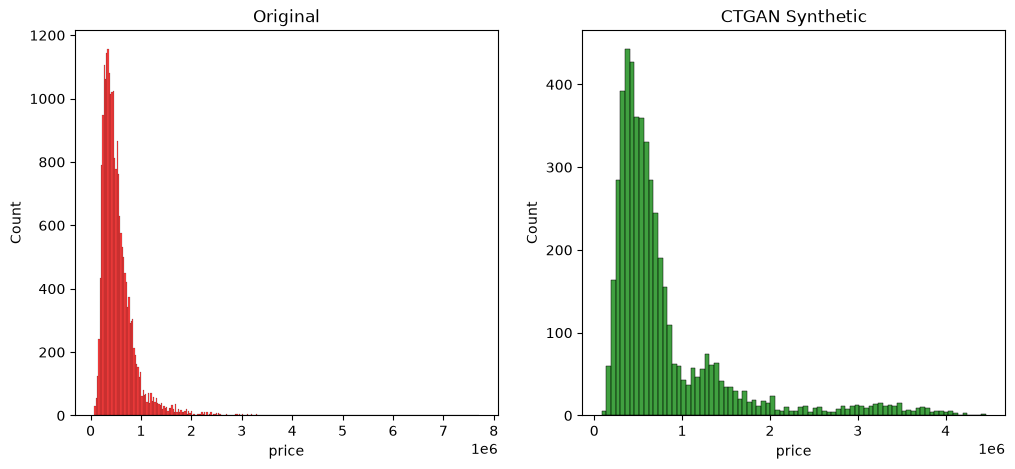

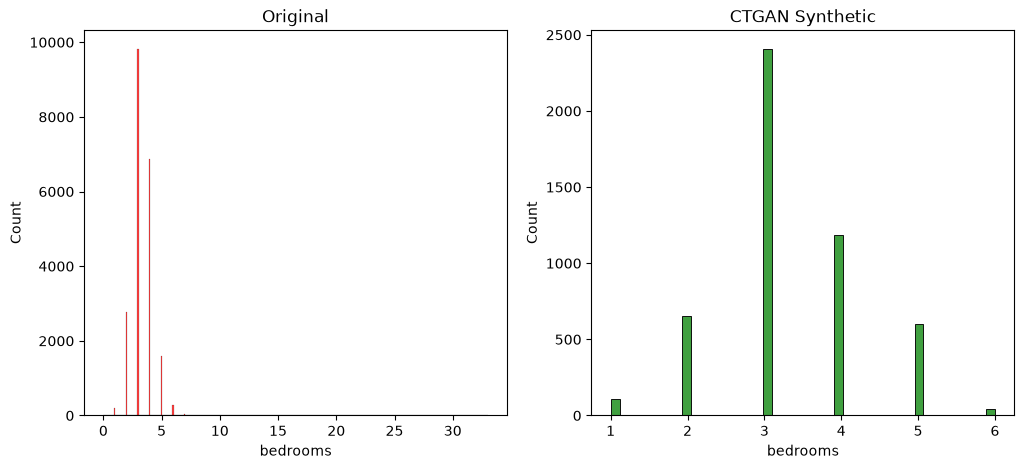

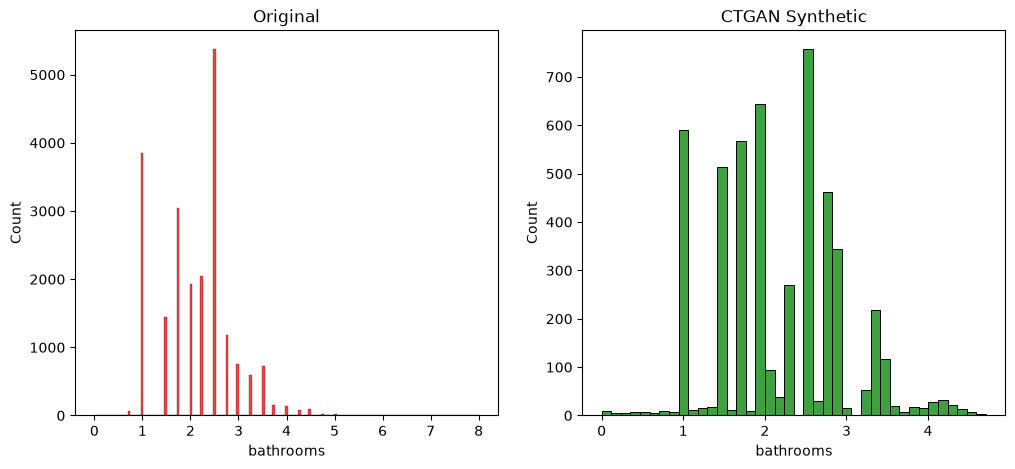

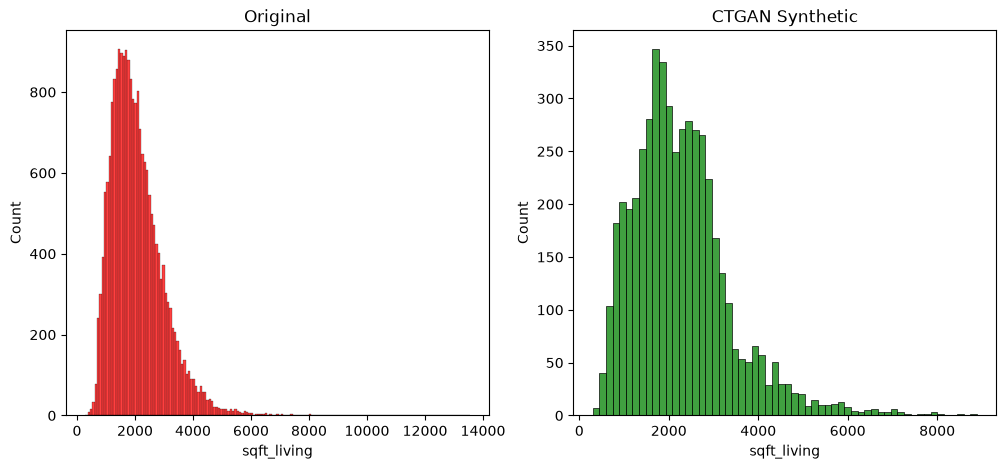

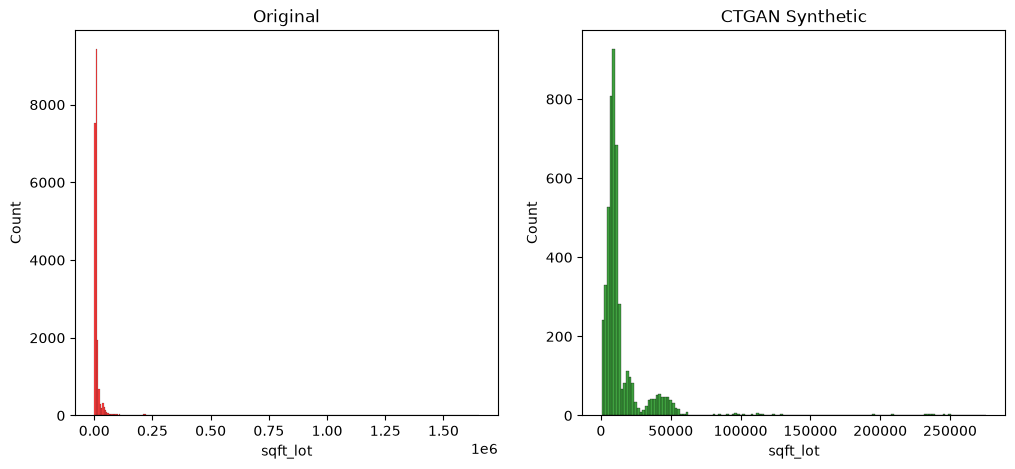

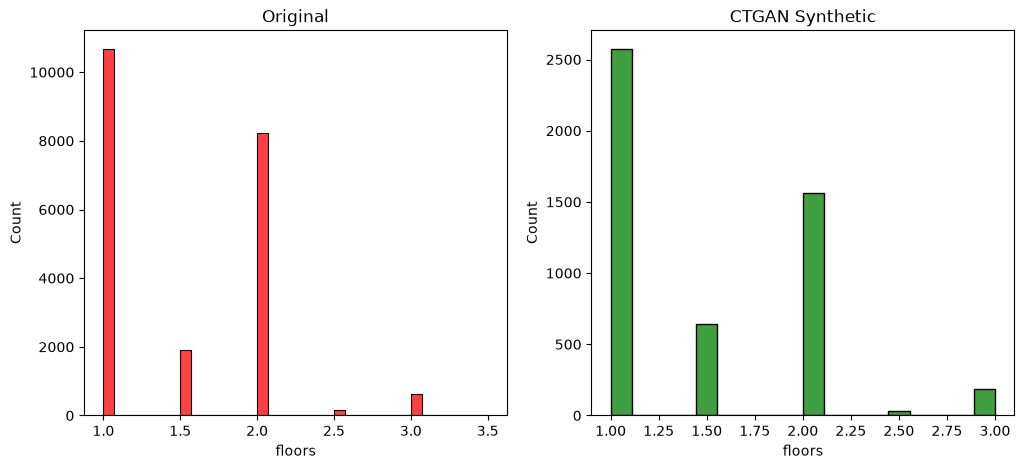

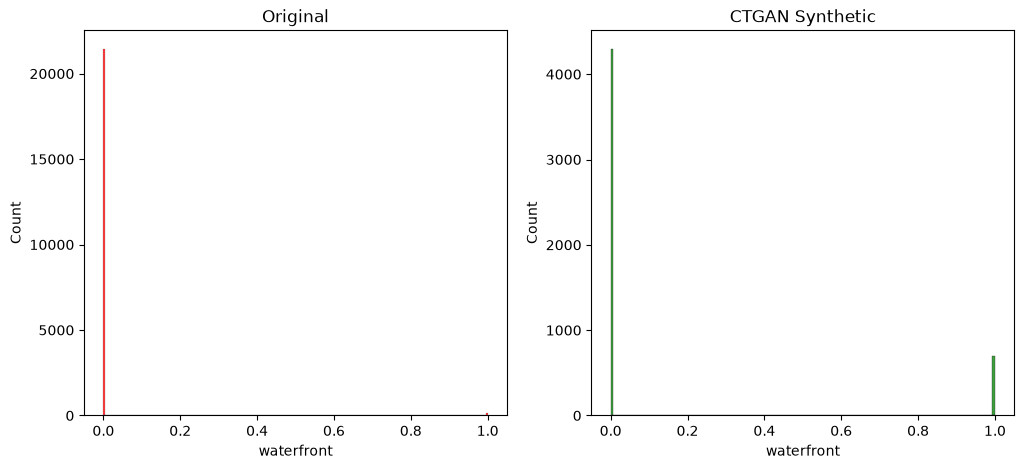

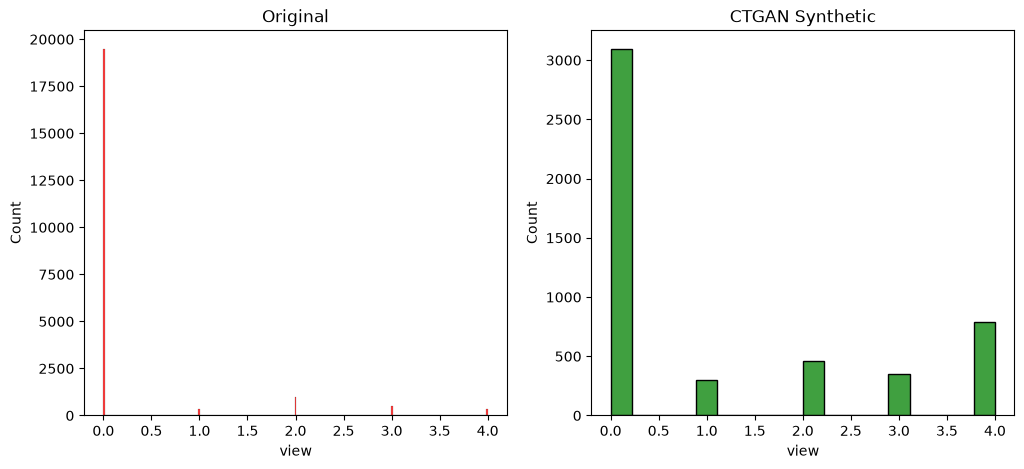

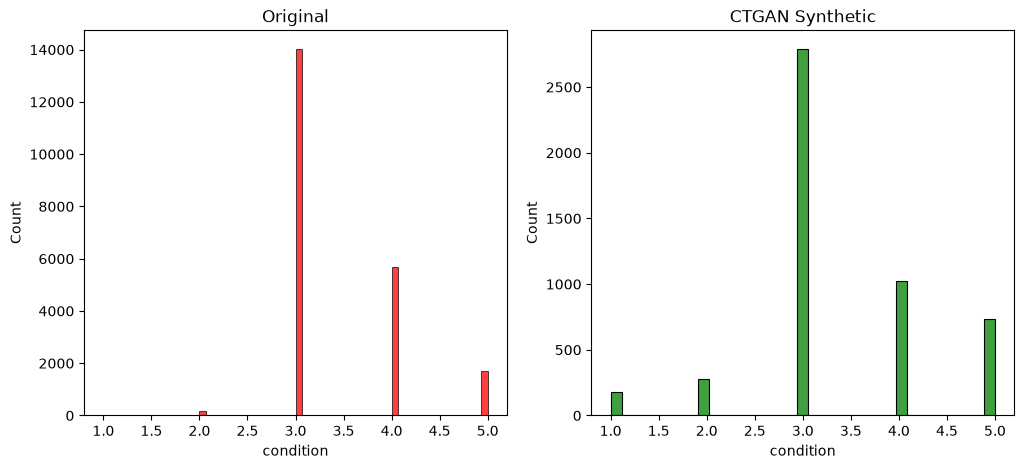

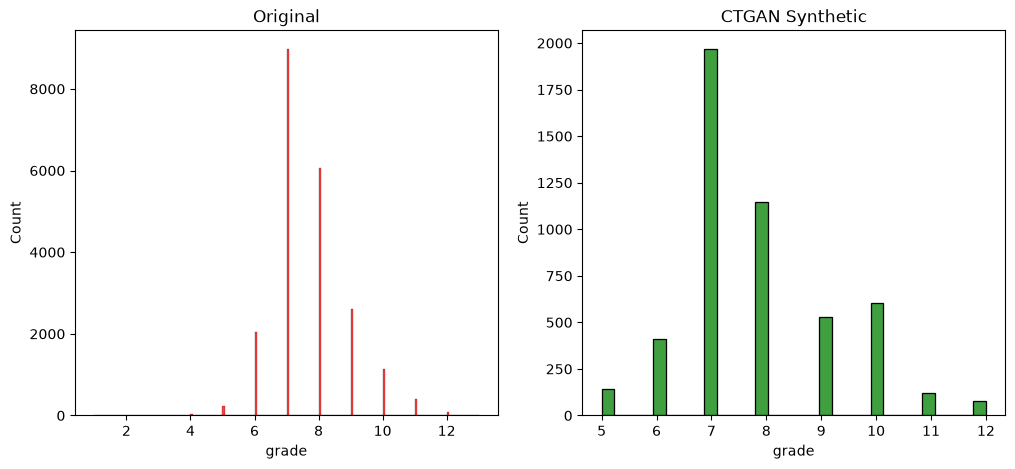

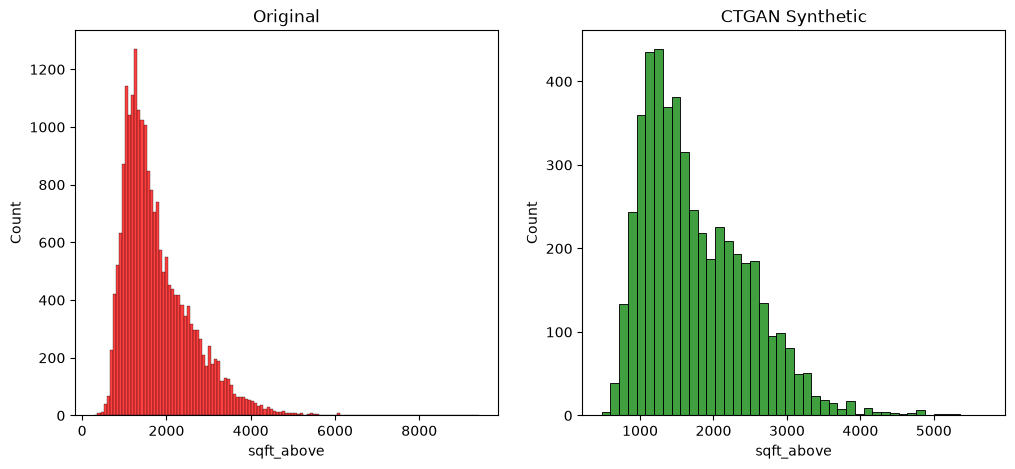

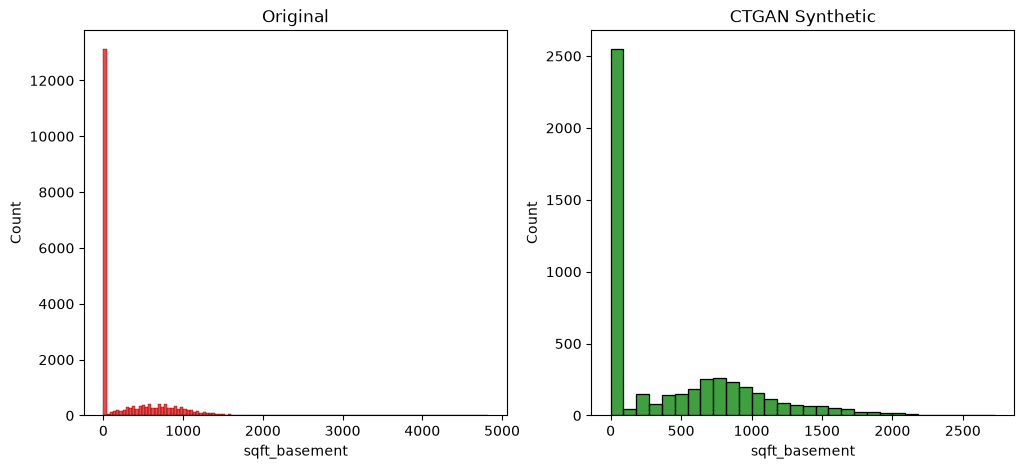

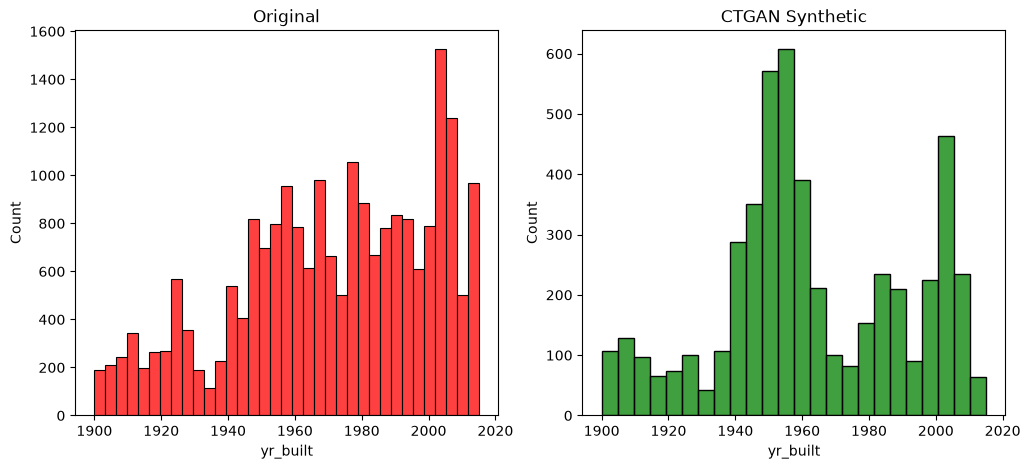

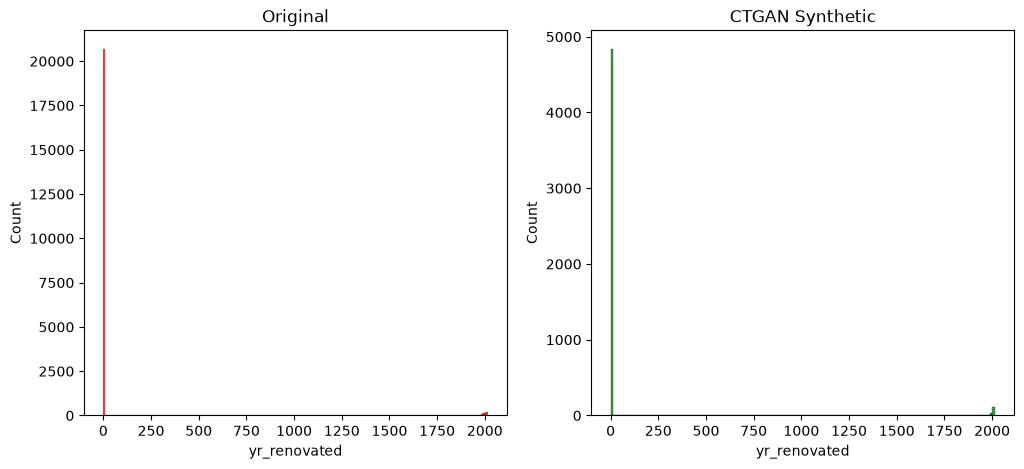

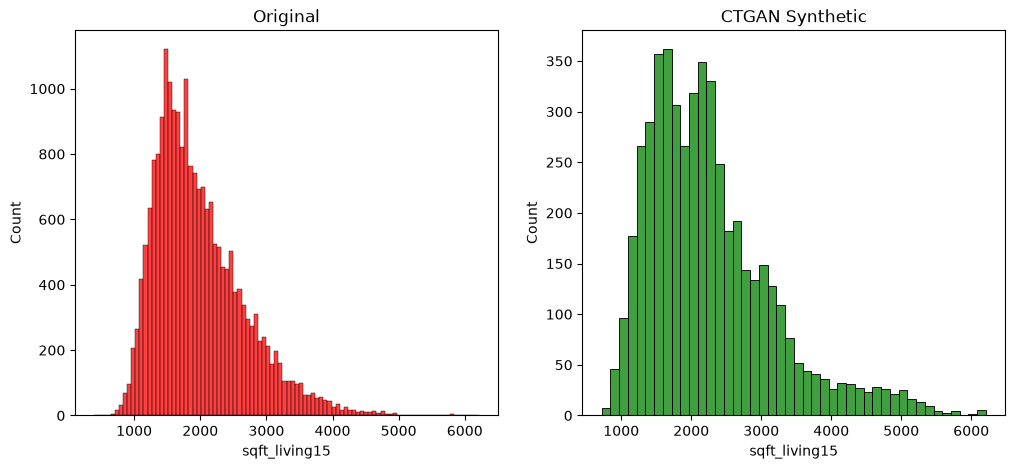

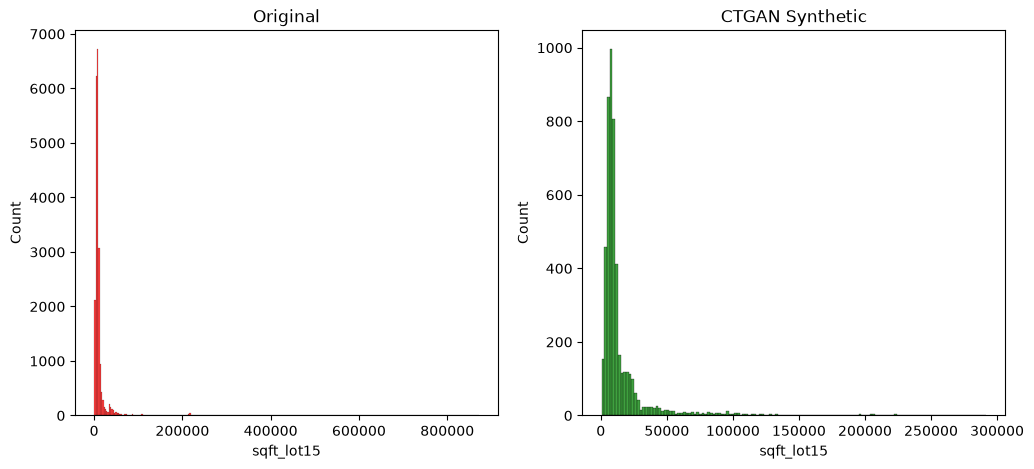

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Let's make two histplots for each column. One for the Original dataset, the other for CTGAN.
for column in df.columns:

    # Create the canvas and insert the original and synthetic histplots
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    sns.histplot(df[column], ax=axes[0], color="red")
    sns.histplot(synthetic_data[column], ax=axes[1], color="green")

    # Set the titles.
    axes[0].set_title("Original")
    axes[1].set_title("CTGAN Synthetic")

In [17]:
df.corr(numeric_only=True).style.background_gradient(cmap="coolwarm", vmin=-1, vmax=1)

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,sqft_living15,sqft_lot15
price,1.000000,0.308350,0.525138,0.702035,0.089661,0.256794,0.266369,0.397293,0.036362,0.667434,0.605567,0.323816,0.054012,0.126434,0.585379,0.082447
bedrooms,0.308350,1.000000,0.515884,0.576671,0.031703,0.175429,-0.006582,0.079532,0.028472,0.356967,0.477600,0.303093,0.154178,0.018841,0.391638,0.029244
bathrooms,0.525138,0.515884,1.000000,0.754665,0.087740,0.500653,0.063744,0.187737,-0.124982,0.664983,0.685342,0.283770,0.506019,0.050739,0.568634,0.087175
sqft_living,0.702035,0.576671,0.754665,1.000000,0.172826,0.353949,0.103818,0.284611,-0.058753,0.762704,0.876597,0.435043,0.318049,0.055363,0.756420,0.183286
sqft_lot,0.089661,0.031703,0.087740,0.172826,1.000000,-0.005201,0.021604,0.074710,-0.008958,0.113621,0.183512,0.015286,0.053080,0.007644,0.144608,0.718557
floors,0.256794,0.175429,0.500653,0.353949,-0.005201,1.000000,0.023698,0.029444,-0.263768,0.458183,0.523885,-0.245705,0.489319,0.006338,0.279885,-0.011269
waterfront,0.266369,-0.006582,0.063744,0.103818,0.021604,0.023698,1.000000,0.401857,0.016653,0.082775,0.072075,0.080588,-0.026161,0.092885,0.086463,0.030703
view,0.397293,0.079532,0.187737,0.284611,0.074710,0.029444,0.401857,1.000000,0.045990,0.251321,0.167649,0.276947,-0.053440,0.103917,0.280439,0.072575
condition,0.036362,0.028472,-0.124982,-0.058753,-0.008958,-0.263768,0.016653,0.045990,1.000000,-0.144674,-0.158214,0.174105,-0.361417,-0.060618,-0.092824,-0.003406
grade,0.667434,0.356967,0.664983,0.762704,0.113621,0.458183,0.082775,0.251321,-0.144674,1.000000,0.755923,0.168392,0.446963,0.014414,0.713202,0.119248


In [12]:
synthetic_data.corr(numeric_only=True).style.background_gradient(cmap="coolwarm", vmin=-1, vmax=1)

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,sqft_living15,sqft_lot15
price,1.000000,0.446509,0.553565,0.649294,0.147523,0.262667,0.557975,0.581613,0.051627,0.649927,0.528264,0.478527,0.165916,0.137358,0.652119,0.123365
bedrooms,0.446509,1.000000,0.571604,0.603685,0.116907,0.234685,0.108470,0.196607,0.126970,0.574339,0.492779,0.410535,0.284371,0.047513,0.548329,0.096081
bathrooms,0.553565,0.571604,1.000000,0.674521,0.158973,0.437349,0.235204,0.326300,0.039846,0.703606,0.630511,0.407048,0.411921,0.088852,0.645519,0.130752
sqft_living,0.649294,0.603685,0.674521,1.000000,0.209402,0.281452,0.271491,0.371482,0.113269,0.731219,0.624594,0.554999,0.296779,0.115373,0.733774,0.176746
sqft_lot,0.147523,0.116907,0.158973,0.209402,1.000000,0.056592,0.098311,0.101025,-0.013876,0.202460,0.244595,0.058045,0.105109,0.032570,0.230523,0.261351
floors,0.262667,0.234685,0.437349,0.281452,0.056592,1.000000,0.128256,0.144162,-0.137094,0.443315,0.493087,-0.066250,0.446594,0.011161,0.315324,0.014425
waterfront,0.557975,0.108470,0.235204,0.271491,0.098311,0.128256,1.000000,0.702542,-0.009165,0.324923,0.236429,0.211890,-0.020052,0.171485,0.328490,0.060616
view,0.581613,0.196607,0.326300,0.371482,0.101025,0.144162,0.702542,1.000000,0.016325,0.406805,0.283342,0.339636,0.007883,0.208518,0.420008,0.099637
condition,0.051627,0.126970,0.039846,0.113269,-0.013876,-0.137094,-0.009165,0.016325,1.000000,0.041611,0.001708,0.194124,-0.086684,-0.003162,0.017441,0.019921
grade,0.649927,0.574339,0.703606,0.731219,0.202460,0.443315,0.324923,0.406805,0.041611,1.000000,0.686144,0.418864,0.409865,0.127515,0.723057,0.169119


In [13]:
df.corr(numeric_only=True)['price']

price           1.00
bedrooms        0.31
bathrooms       0.53
sqft_living     0.70
sqft_lot        0.09
floors          0.26
waterfront      0.27
view            0.40
condition       0.04
grade           0.67
sqft_above      0.61
sqft_basement   0.32
yr_built        0.05
yr_renovated    0.13
sqft_living15   0.59
sqft_lot15      0.08
Name: price, dtype: float64

In [14]:
synthetic_data.corr(numeric_only=True)['price']

price           1.00
bedrooms        0.45
bathrooms       0.55
sqft_living     0.65
sqft_lot        0.15
floors          0.26
waterfront      0.56
view            0.58
condition       0.05
grade           0.65
sqft_above      0.53
sqft_basement   0.48
yr_built        0.17
yr_renovated    0.14
sqft_living15   0.65
sqft_lot15      0.12
Name: price, dtype: float64

In [18]:
synthetic_data

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,sqft_living15,sqft_lot15
0,709445.00,3,2.24,2476,19819,1.00,0,0,3,7,1881,937,1957,1,2461,18170
1,860837.00,2,3.56,2605,13842,2.00,1,4,3,9,2279,3,1963,1990,2800,11160
2,2338624.00,5,3.47,4045,9437,2.00,0,4,3,11,3252,663,2005,0,3436,7817
3,527307.00,4,2.85,2795,10250,1.00,0,0,3,7,1102,1003,1939,1,2408,8564
4,396826.00,3,2.50,3191,5958,1.00,0,0,3,8,1405,686,1965,0,2041,6802
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,977005.00,5,2.51,2629,10355,2.00,0,0,1,10,2550,994,2002,2,3169,18500
4996,284504.00,3,2.00,1932,6824,1.00,0,0,4,8,1577,746,1965,1,1705,4206
4997,268472.00,4,1.97,1120,7958,1.50,0,0,2,7,806,2,1955,0,2098,8505
4998,3397736.00,4,3.49,6985,34509,2.00,1,2,5,11,5350,1683,1978,1,4829,14727
